In [1]:
import pandas as pd 
import seaborn as sns


Matplotlib created a temporary cache directory at /var/folders/nm/yz2z8w796mz79tfcqshfwxtr0000gr/T/matplotlib-xp03omo1 because the default path (/Users/pujakadayat/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
df = pd.read_csv('PCOS_infertility.csv')
df

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
0,1,10001,0,1.99,1.99,2.07
1,2,10002,0,60.80,1.99,1.53
2,3,10003,1,494.08,494.08,6.63
3,4,10004,0,1.99,1.99,1.22
4,5,10005,0,801.45,801.45,2.26
...,...,...,...,...,...,...
536,537,10537,0,1.99,1.99,1.7
537,538,10538,0,80.13,1.99,5.6
538,539,10539,0,1.99,1.99,3.7
539,540,10540,0,292.92,1.99,5.2


In [3]:
df.columns

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', '  I   beta-HCG(mIU/mL)',
       'II    beta-HCG(mIU/mL)', 'AMH(ng/mL)'],
      dtype='object')

In [4]:
df.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
  I   beta-HCG(mIU/mL)    0
II    beta-HCG(mIU/mL)    0
AMH(ng/mL)                0
dtype: int64

In [5]:
df.dtypes

Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
  I   beta-HCG(mIU/mL)    float64
II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                 object
dtype: object

In [6]:
df['AMH(ng/mL)'].map(type).value_counts()

AMH(ng/mL)
<class 'str'>    541
Name: count, dtype: int64

In [7]:
def is_numeric_string(x):
    try:
        float(x)
        return True
    except (ValueError,TypeError):
        return False
       


In [8]:
mask = df['AMH(ng/mL)'].map(is_numeric_string)
df[~mask]

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
305,306,10306,0,42.0,1.99,a


In [9]:
df['AMH(ng/mL)'] = pd.to_numeric(df['AMH(ng/mL)'], errors = 'coerce')

In [14]:
df.dtypes

Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
  I   beta-HCG(mIU/mL)    float64
II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                float64
dtype: object

In [30]:

df[~mask] = df[~mask].fillna(df['AMH(ng/mL)'].mean(numeric_only=True))

In [27]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

In [31]:
df.loc[305]

Sl. No                      306.000000
Patient File No.          10306.000000
PCOS (Y/N)                    0.000000
  I   beta-HCG(mIU/mL)       42.000000
II    beta-HCG(mIU/mL)        1.990000
AMH(ng/mL)                    5.624191
Name: 305, dtype: float64

In [ ]:
df_group = df.groupby('PCOS (Y/N)')

In [33]:
df_group.mean()

,Sl. No,Patient File No.,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
PCOS (Y/N),,,,,
0,264.357143,10264.357143,728.982437,223.975137,4.544470
1,284.661017,10284.661017,532.042537,267.543613,7.844633


In [41]:
df.groupby('PCOS (Y/N)')[['  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)']].mean()

,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL)
PCOS (Y/N),,
0,728.982437,223.975137
1,532.042537,267.543613


In [43]:
df.groupby('PCOS (Y/N)')['AMH(ng/mL)'].std()

PCOS (Y/N)
0    4.285040
1    7.791138
Name: AMH(ng/mL), dtype: float64

>= 3.0(ng/ml) AMh level in woman whom already has a pcos  diagnosis showed significant structural changes in their ovaries (ovarian morphology) compared to those with lower AMH levels. 

"AMH differs meaningfully by PCOS status; tested against a clinical threshold from literature — details in README."

In [55]:
df['PCOS-related Ovarian Changes'] = df['AMH(ng/mL)'] >= 3.9

In [53]:
df.groupby('PCOS (Y/N)')['PCOS-related Ovarian Changes'].mean()

PCOS (Y/N)
0    0.403846
1    0.649718
Name: PCOS-related Ovarian Changes, dtype: float64

<Axes: xlabel='PCOS (Y/N)', ylabel='AMH(ng/mL)'>

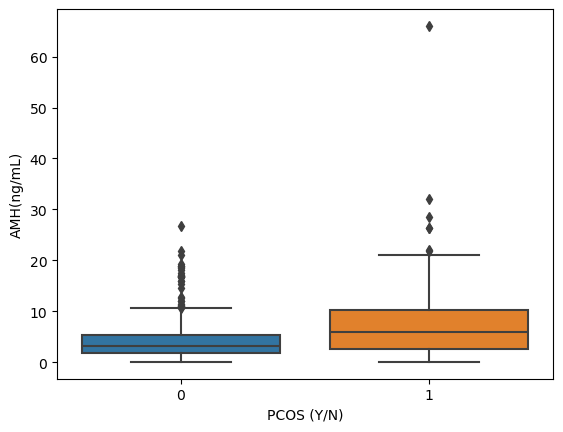

In [56]:
sns.boxplot(df,x='PCOS (Y/N)', y='AMH(ng/mL)')

In [57]:
df[(df['PCOS (Y/N)'] == 1) & (df['AMH(ng/mL)'] > 15)]

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL),PCOS-related Ovarian Changes
108,109,10109,1,397.08,3893.060000,16.9,True
113,114,10114,1,332.51,2.000000,21.0,True
122,123,10123,1,138.68,586.060000,17.9,True
123,124,10124,1,1.99,0.110417,19.8,True
133,134,10134,1,342.16,1.990000,19.0,True
142,143,10143,1,1.99,1.990000,18.4,True
150,151,10151,1,232.71,232.710000,15.9,True
180,181,10181,1,1.99,1.990000,32.0,True
213,214,10214,1,144.63,144.630000,26.4,True
217,218,10218,1,1.99,99.690000,22.0,True


In [58]:
df[(df['PCOS (Y/N)'] == 0) & (df['AMH(ng/mL)'] > 15)]

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL),PCOS-related Ovarian Changes
109,110,10110,0,926.24,600.23,17.0,True
110,111,10111,0,26290.26,3350.19,21.9,True
131,132,10132,0,1.99,1.99,19.3,True
139,140,10140,0,1.99,1.99,17.1,True
212,213,10213,0,1.99,1.99,16.9,True
231,232,10232,0,150.91,150.91,16.7,True
233,234,10234,0,392.73,1.99,16.8,True
263,264,10264,0,3.25,4.76,16.8,True
264,265,10265,0,165.61,1.99,16.9,True
268,269,10269,0,100.58,1.99,26.8,True


In [64]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

feature_cols = ['  I   beta-HCG(mIU/mL)','II    beta-HCG(mIU/mL)','AMH(ng/mL)']
X= df[feature_cols]
y= df['PCOS (Y/N)']

X_train,X_test, y_train,y_test = train_test_split(X,y,test_size= 0.2, stratify=y,random_state=42)

model = LogisticRegression()
model.fit(X_train,y_train)


LogisticRegression()

In [65]:
X_train.shape
X_test.shape

(109, 3)

In [67]:
y_prediction = model.predict(X_test)
y_prediction


array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [68]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_prediction)

0.6422018348623854

In [69]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_prediction))

              precision    recall  f1-score   support

           0       0.67      0.90      0.77        73
           1       0.36      0.11      0.17        36

    accuracy                           0.64       109
   macro avg       0.52      0.51      0.47       109
weighted avg       0.57      0.64      0.57       109



In [71]:
X_train.describe()

,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
count,432.000000,432.000000,432.000000
mean,589.452884,224.404582,5.735109
std,3027.577337,1607.641325,5.990705
min,1.300000,0.110417,0.100000
25%,1.990000,1.990000,2.100000
50%,14.915000,1.990000,3.740000
75%,296.375000,75.537500,7.065000
max,30007.000000,25000.000000,66.000000
